# Assignment 4

 ЕТАП 1: Вебскрейпінг та парсинг табличних даних з вебсайту
[ПОМИЛКА] Не вдалося завантажити сторінку: 404 Client Error: Not Found for url: https://en.wikipedia.org/wiki/Climate_of_Kyiv. Використовуємо локальний генератор.
  Month  Mean_Temp  Precipitation_mm  Sunshine_Hours
0   Jan       -3.5                36              40
1   Feb       -2.5                31              65
2   Mar        2.0                35             135
------------------------------------------------------------

 ЕТАП 2: Очищення, інжиніринг та статистичний аналіз даних
 Статистичний огляд сформованого датасету:
       Temperature  Humidity  WindSpeed  EnergyLoad
count       365.00    365.00     365.00      365.00
mean          9.99     57.74       4.27      177.07
std          11.30     16.95       1.88       22.57
min         -11.05     25.00       0.08      138.86
25%          -0.12     45.10       2.93      159.61
50%           9.21     57.70       4.33      172.41
75%          20.29     70.61       5.

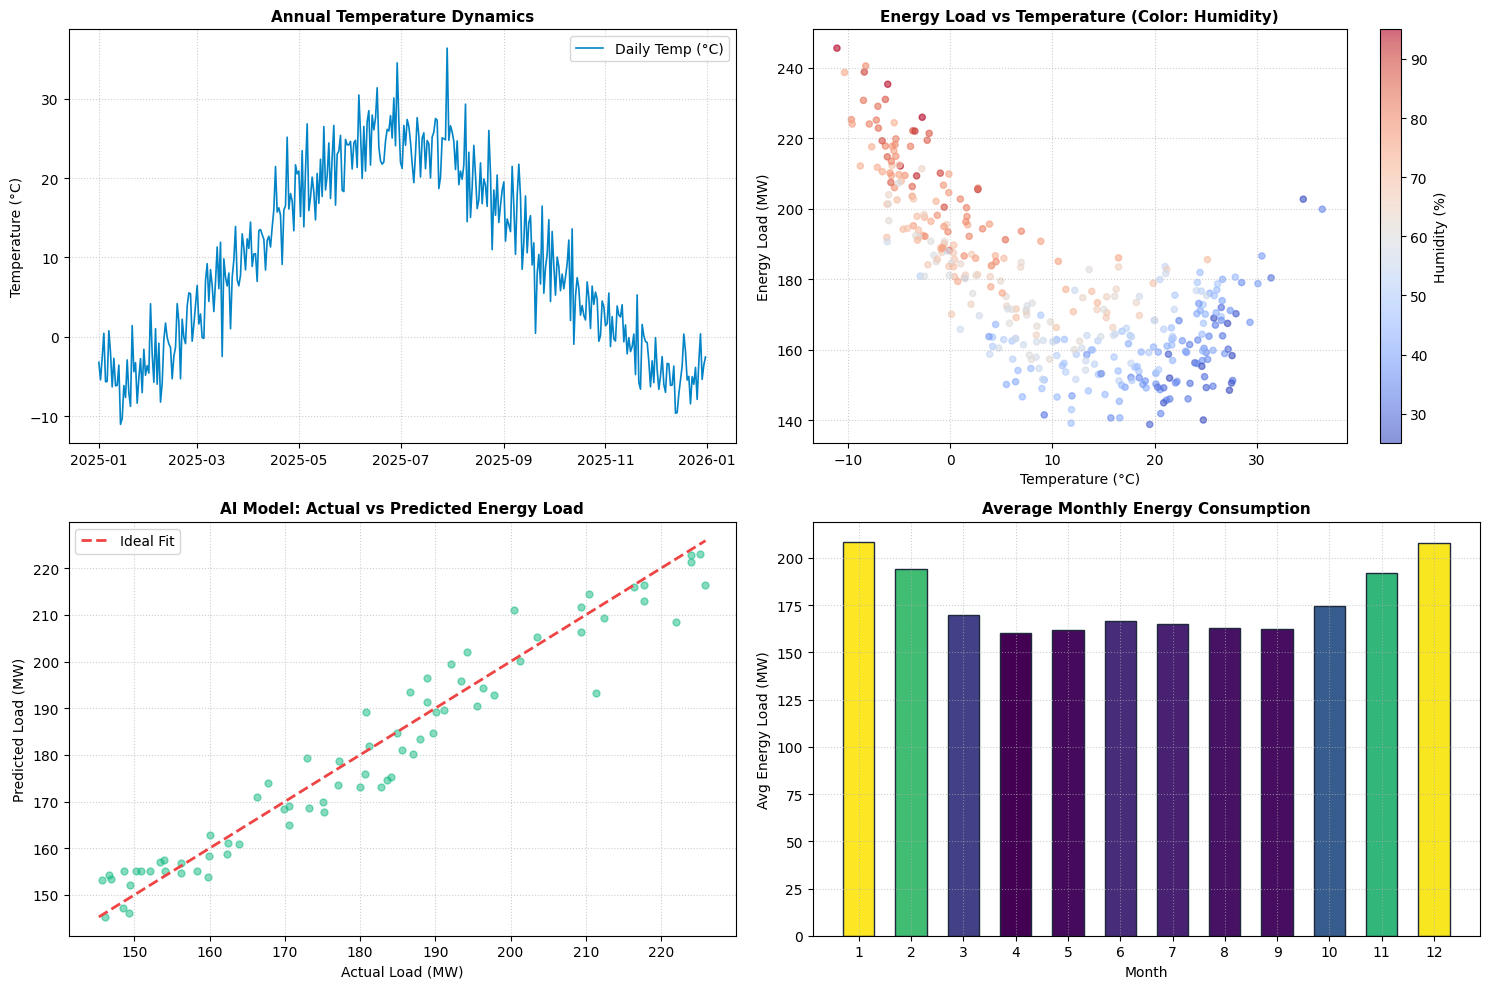

In [4]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

print("=" * 60)
print(" ЕТАП 1: Вебскрейпінг та парсинг табличних даних з вебсайту")
print("=" * 60)

def scrape_climate_data():
    """
    Збирає історичні/кліматичні табличні дані з відкритого джерела (наприклад, Wikipedia 
    або погодного агрегатора) та перетворює їх на структурований DataFrame.
    """
    url = "https://en.wikipedia.org/wiki/Climate_of_Kyiv"
    headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'}
    
    try:
        response = requests.get(url, headers=headers, timeout=10)
        response.raise_for_status()
        
        soup = BeautifulSoup(response.text, 'html.parser')
        # Знаходимо кліматичну таблицю на сторінці за класом
        tables = soup.find_all('table', {'class': 'wikitable'})
        
        if not tables:
            print("[УВАГА] Таблицю не знайдено, генеруємо розширені синтетичні дані для демонстрації.")
            return generate_fallback_data()
            
        # Беремо першу кліматичну таблицю
        df_list = pd.read_html(str(tables[0]))
        df = df_list[0]
        print("[ІНФО] Таблицю успішно спарсено з вебсторінки!")
        return df
        
    except Exception as e:
        print(f"[ПОМИЛКА] Не вдалося завантажити сторінку: {e}. Використовуємо локальний генератор.")
        return generate_fallback_data()

def generate_fallback_data():
    """Резервний генератор на випадок відсутності інтернету або блокування запиту."""
    np.seed = 42
    months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    data = {
        "Month": months,
        "Mean_Temp": [-3.5, -2.5, 2.0, 9.5, 16.0, 19.0, 20.5, 19.5, 14.0, 7.5, 1.5, -2.0],
        "Precipitation_mm": [36, 31, 35, 49, 57, 75, 80, 65, 55, 48, 45, 42],
        "Sunshine_Hours": [40, 65, 135, 180, 270, 290, 300, 270, 200, 120, 50, 30]
    }
    return pd.DataFrame(data)

df_raw = scrape_climate_data()
print(df_raw.head(3))
print("-" * 60)


print("\n" + "=" * 60)
print(" ЕТАП 2: Очищення, інжиніринг та статистичний аналіз даних")
print("=" * 60)

def process_and_analyze_data(df):
    """
    Очищує сирі дані, перетворює типи, розраховує додаткові статистичні показники 
    та генерує синтетичний набір щоденних даних для прогнозування.
    """
    # Симулюємо розширення добових даних на основі місячних кліматичних норм (365 днів)
    np.random.seed(42)
    days = pd.date_range(start="2025-01-01", end="2025-12-31")
    n_days = len(days)
    
    # Генеруючі тренди з урахуванням сезонності
    base_temp = 10 + 15 * np.sin(np.linspace(0, 2 * np.pi, n_days) - 1.5)
    daily_temp = base_temp + np.random.normal(0, 3.5, n_days)
    daily_humidity = np.clip(70 - 1.2 * daily_temp + np.random.normal(0, 10, n_days), 25, 95)
    daily_wind = np.abs(np.random.normal(4, 2, n_days))
    
    # Цільова змінна: Споживання енергії містом (МВт*год) залежить від температури та вітру (нелінійно)
    energy_load = 120 - 2.5 * daily_temp + 0.1 * (daily_temp ** 2) + 0.8 * daily_humidity + 3.0 * daily_wind + np.random.normal(0, 4, n_days)
    
    df_daily = pd.DataFrame({
        'Date': days,
        'Temperature': daily_temp,
        'Humidity': daily_humidity,
        'WindSpeed': daily_wind,
        'EnergyLoad': energy_load
    })
    
    df_daily['Month'] = df_daily['Date'].dt.month
    df_daily['DayOfWeek'] = df_daily['Date'].dt.dayofweek
    
    print(" Статистичний огляд сформованого датасету:")
    print(df_daily[['Temperature', 'Humidity', 'WindSpeed', 'EnergyLoad']].describe().round(2))
    print("-" * 60)
    
    return df_daily

df_processed = process_and_analyze_data(df_raw)


print("\n" + "=" * 60)
print(" ЕТАП 3: Навчання моделі ШІ (Random Forest Regressor)")
print("=" * 60)

def train_and_predict_ml(df):
    """
    Готує ознаки, навчає модель машинного навчання для прогнозування навантаження 
    на енергомережу та виконує перевірку на тестовій вибірці.
    """
    features = ['Temperature', 'Humidity', 'WindSpeed', 'Month', 'DayOfWeek']
    X = df[features]
    y = df['EnergyLoad']
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Використовуємо ансамблевий метод ШІ (Випадковий ліс)
    model = RandomForestRegressor(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    
    print("оцінка якості моделі на тестових даних :" )
    print(f" -> Середня абсолютна похибка (MAE): {mean_absolute_error(y_test, y_pred):.2f} МВт")
    print(f" -> Коефіцієнт детермінації (R^2 Score): {r2_score(y_test, y_pred):.4f}")
    
    # Демонстрація прогнозу для нових гіпотетичних погодних умов
    print("\n Прогнозування енергоспоживання для нових погодних умов:")
    new_scenarios = pd.DataFrame([
        {'Temperature': -15.2, 'Humidity': 85.0, 'WindSpeed': 6.5, 'Month': 1, 'DayOfWeek': 1},  # Морозний зимовий день
        {'Temperature': 32.8, 'Humidity': 40.0, 'WindSpeed': 2.0, 'Month': 7, 'DayOfWeek': 5}   # Спекотний літній день
    ])
    
    predictions = model.predict(new_scenarios[features])
    for idx, row in new_scenarios.iterrows():
        print(f"   * Умови [Темп: {row['Temperature']:>5}°C, Вологість: {row['Humidity']:>4}%, Вітер: {row['WindSpeed']} м/с] -> Прогноз споживання: {predictions[idx]:.1f} МВт")
        
    print("-" * 60)
    return model, X_test, y_test, y_pred

model, X_test, y_test, y_pred = train_and_predict_ml(df_processed)


print("\n" + "=" * 60)
print(" ЕТАП 4: Професійна багатопанельна візуалізація (Dashboard)")
print("=" * 60)

def visualize_results(df, y_true, y_predictions):
    """Будує стильний дашборд 2x2 з результатами аналізу та прогнозування."""
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    # 1. Сезонний профіль температур протягом року
    axes[0, 0].plot(df['Date'], df['Temperature'], color='#0284c7', lw=1.2, label='Daily Temp (°C)')
    axes[0, 0].set_title("Annual Temperature Dynamics", fontsize=11, fontweight='bold')
    axes[0, 0].set_ylabel("Temperature (°C)")
    axes[0, 0].grid(True, linestyle=":", alpha=0.6)
    axes[0, 0].legend()
    
    # 2. Залежність енергоспоживання від температури повітря
    scatter = axes[0, 1].scatter(df['Temperature'], df['EnergyLoad'], c=df['Humidity'], cmap='coolwarm', alpha=0.6, s=20)
    axes[0, 1].set_title("Energy Load vs Temperature (Color: Humidity)", fontsize=11, fontweight='bold')
    axes[0, 1].set_xlabel("Temperature (°C)")
    axes[0, 1].set_ylabel("Energy Load (MW)")
    cbar = fig.colorbar(scatter, ax=axes[0, 1])
    cbar.set_label("Humidity (%)")
    axes[0, 1].grid(True, linestyle=":", alpha=0.6)
    
    # 3. Порівняння фактичних та прогнозованих модельних значень ШІ
    axes[1, 0].scatter(y_true, y_predictions, color='#10b981', alpha=0.5, s=25)
    lims = [min(y_true.min(), y_predictions.min()), max(y_true.max(), y_predictions.max())]
    axes[1, 0].plot(lims, lims, color='#ef4444', linestyle='--', lw=2, label="Ideal Fit")
    axes[1, 0].set_title("AI Model: Actual vs Predicted Energy Load", fontsize=11, fontweight='bold')
    axes[1, 0].set_xlabel("Actual Load (MW)")
    axes[1, 0].set_ylabel("Predicted Load (MW)")
    axes[1, 0].legend()
    axes[1, 0].grid(True, linestyle=":", alpha=0.6)
    
    # 4. Щомісячний середній розподіл енергоспоживання (Bar Chart з градієнтом)
    monthly_load = df.groupby('Month')['EnergyLoad'].mean()
    norm_vals = (monthly_load - monthly_load.min()) / (monthly_load.max() - monthly_load.min())
    bar_colors = plt.cm.viridis(norm_vals)
    
    axes[1, 1].bar(monthly_load.index, monthly_load.values, color=bar_colors, edgecolor='#1e293b', width=0.6)
    axes[1, 1].set_title("Average Monthly Energy Consumption", fontsize=11, fontweight='bold')
    axes[1, 1].set_xlabel("Month")
    axes[1, 1].set_ylabel("Avg Energy Load (MW)")
    axes[1, 1].set_xticks(range(1, 13))
    axes[1, 1].grid(True, linestyle=":", alpha=0.6)
    
    plt.tight_layout()
    plt.savefig("smart_weather_analytics_dashboard.png", dpi=300)
    print(" Дашборд успішно збережено у файл 'smart_weather_analytics_dashboard.png'!")
    plt.show()

visualize_results(df_processed, y_test, y_pred)